In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
from pathlib import Path

In [3]:
zip_path = Path(
     "/content/drive/MyDrive/PPE/"
    "Construction-Hazard-Detection.v97i.yolov8.zip"
)

extract_path = Path(
    "/content/drive/MyDrive/PPE/PPEGuard_Data/raw/"
)

# create the data folder
extract_path.mkdir(parents=True, exist_ok=True)

# extract the zip files
if (extract_path / "README.dataset.txt").exists() or (extract_path / "data.yaml").exists():
    print("Dataset already extracted")
else:
  with zipfile.ZipFile(zip_path, "r") as zip_ref:
      zip_ref.extractall(extract_path)

print("Dataset extraction completed")

Dataset already extracted
Dataset extraction completed


# Phase 1: Dataset Loading and Structural Inspection

## 1.1 Dataset Structure Verification

The objective of this section is to verify the extracted dataset, inspect its directory structure, and identify the location of the images, annotation files and dataset configuration.

The original dataset will remain unchanged throughout the experimentation process.

In [4]:
# inspect the top-level contents
for item in extract_path.iterdir():
  if item.is_dir():
    print(f"[DIRETORY] {item.name}")

  else:
    print(f"[FILE] {item.name}")

[DIRETORY] train
[FILE] data.yaml
[FILE] README.roboflow.txt
[FILE] README.dataset.txt


In [5]:
dataset_path = extract_path

train_path = dataset_path / "train"

for item in train_path.iterdir():
  if item.is_dir():
        print(f"[DIRECTORY] {item.name}")
  else:
        print(f"[FILE] {item.name}")


[DIRECTORY] images
[DIRECTORY] labels


In [6]:
# count images and annotation files

image_path = train_path / "images"
label_path = train_path / "labels"

image_extentions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    file for file in image_path.iterdir() if file.suffix.lower() in image_extentions

]

label_file = list(label_path.glob("*.txt"))

print(f"Number of images: {len(image_files)}")
print(f"Number of labels: {len(label_file):,}")

Number of images: 6689
Number of labels: 6,689


In [7]:
# check image-label correspondence
# Extract image and annotation filenames without extensions

image_stems = {file.stem for file in image_files}
label_stems = {file.stem for file in label_file}


# Identify unmatched files
images_without_labels = image_stems - label_stems
labels_without_images = label_stems - image_stems

print(f"Images without labels: {len(images_without_labels)}")
print(f"Labels without images: {len(labels_without_images)}")

Images without labels: 0
Labels without images: 0


In [8]:
# Identify empty annotation files
empty_labels = [
    file for file in label_file
    if file.stat().st_size == 0
]

print(f"Total empty annotation files: {len(empty_labels)}")

Total empty annotation files: 156


In [9]:
# Display the first 10 empty annotation files

for label_file in empty_labels[:10]:
    image_file = image_path / f"{label_file.stem}.jpg"

    print(f"Label: {label_file.name}")
    print(f"Image exists: {image_file.exists()}")
    print("-" * 40)

Label: -39-_png.rf.fd2a1c9c931880d788d5df94859cf4ba.txt
Image exists: True
----------------------------------------
Label: LINE_ALBUM_1140324-I-G11_250324_4_jpg.rf.f78352d00bcde8028e35faca09025f3f.txt
Image exists: True
----------------------------------------
Label: LINE_ALBUM_-114-03-24_250324_12_jpg.rf.c711378f13d640cad9df24ab2b8187af.txt
Image exists: True
----------------------------------------
Label: LINE_ALBUM_1140324-I-G30_250324_4_jpg.rf.6859e1d44c4b2745660ce0e114563131.txt
Image exists: True
----------------------------------------
Label: LINE_ALBUM_1140324-_250324_3_jpg.rf.2c17fa62c501eb469124ff6077de76b0.txt
Image exists: True
----------------------------------------
Label: LINE_ALBUM_2024-3-23-_1_240325_5_jpg.rf.ff05c9244510914d9dea1f252c779280.txt
Image exists: True
----------------------------------------
Label: -16-_png.rf.76b51365456a8ffa7e6bf698889a641b.txt
Image exists: True
----------------------------------------
Label: -28-_png.rf.9c4ed23805f2048e772b3029f8c6136e

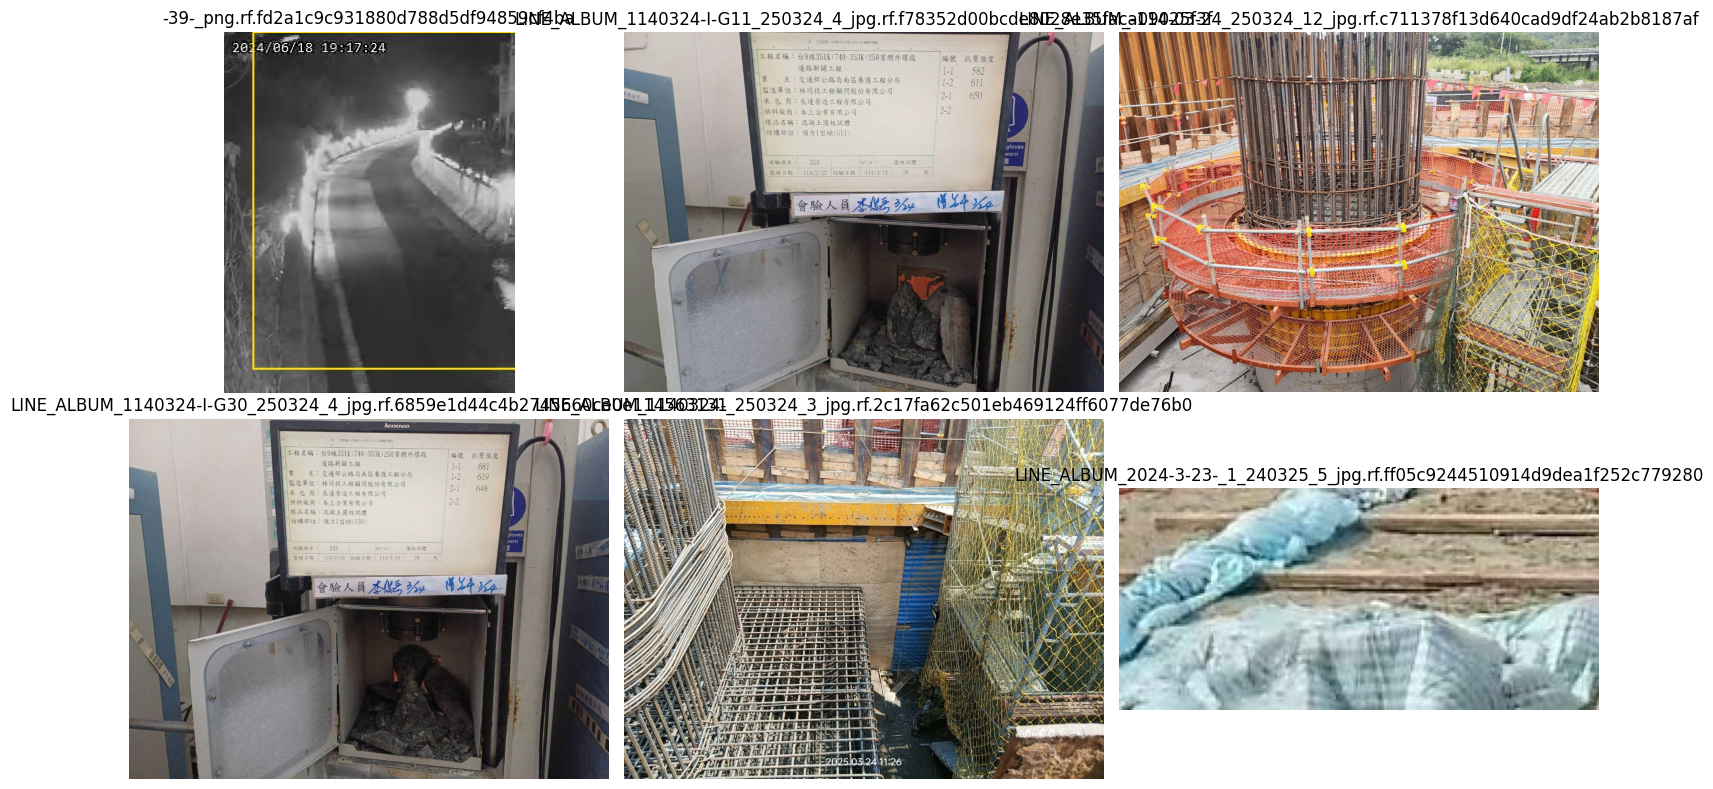

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, label_file in zip(axes.flat, empty_labels[:6]):
    image_file = image_path / f"{label_file.stem}.jpg"

    if image_file.exists():
        image = Image.open(image_file)
        ax.imshow(image)
        ax.set_title(label_file.stem)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [11]:
fig, axes = plt.subplots(4, 6, figsize=(20, 15))

for ax, label_file in zip(axes.flat, empty_labels[6:31]):

  image_file = image_path / f"{label_file.stem}.jpg"

  if image_file.exists():
    image = Image.open(image_file)
    ax.imshow(image)
    ax.set_title(label_file.stem)
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [12]:
import yaml

yaml_path = dataset_path / "data.yaml"

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print(data_config)

{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 11, 'names': ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'utility pole', 'vehicle'], 'roboflow': {'workspace': 'object-detection-qn97p', 'project': 'construction-hazard-detection', 'version': 97, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/object-detection-qn97p/construction-hazard-detection/dataset/97'}}


In [13]:
# Find the first non-empty annotation file by globbing the path directly
sample_label = next(
    file for file in label_path.glob("*.txt")
    if file.stat().st_size > 0
)

print(f"Annotation file: {sample_label.name}")
print(sample_label.read_text())

Annotation file: IMG_2251_PNG.rf.c38f2c3acadbf3f399b429b8de2d4a4d.txt
8 0.8866550522648083 0.877065637065637 0.12825783972125437 0.1901930501930502
6 0.8114285714285714 0.9614671814671815 0.02254355400696864 0.04756756756756757
6 0.777595818815331 0.9798841698841698 0.014634146341463415 0.04027027027027027
6 0.895993031358885 0.9624324324324325 0.02191637630662021 0.04857142857142857
6 0.961602787456446 0.9428957528957529 0.015993031358885017 0.05054054054054054
6 0.9718118466898955 0.9033976833976833 0.014982578397212542 0.04366795366795367


In [14]:
import numpy as np

# Annotation validation counters
total_boxes = 0
malformed_rows = []
invalid_class_ids = []
invalid_coordinates = []

# Glob files directly to avoid the overwritten label_file variable
for label_file_path in label_path.glob("*.txt"):

    with open(label_file_path, "r") as file:
        for line_number, line in enumerate(file, start=1):

            values = line.strip().split()

            # Check number of values
            if len(values) != 5:
                malformed_rows.append((label_file_path.name, line_number))
                continue

            try:
                class_id = int(values[0])
                coordinates = np.array(values[1:], dtype=float)
            except ValueError:
                malformed_rows.append((label_file_path.name, line_number))
                continue

            # Check class ID
            if not 0 <= class_id < data_config["nc"]:
                invalid_class_ids.append(
                    (label_file_path.name, line_number, class_id)
                )

            # Check normalized coordinates
            if not np.all(np.isfinite(coordinates)) or not np.all(
                (coordinates >= 0) & (coordinates <= 1)
            ):
                invalid_coordinates.append(
                    (label_file_path.name, line_number, coordinates.tolist())
                )

            total_boxes += 1

print(f"Total bounding boxes: {total_boxes:,}")
print(f"Malformed rows: {len(malformed_rows)}")
print(f"Invalid class IDs: {len(invalid_class_ids)}")
print(f"Invalid coordinates: {len(invalid_coordinates)}")

Total bounding boxes: 61,987
Malformed rows: 0
Invalid class IDs: 0
Invalid coordinates: 0


# Phase 2: Exploratory Data Analysis (EDA)

## Objective
Explore the statistical characteristics of the dataset to understand class distribution, object representation, bounding-box properties, and image dimensions before model training.

## Steps

1. **Class Distribution Analysis:** Examine the number and percentage of bounding boxes belonging to each class.

2. **Image-Level Class Distribution:** Determine how many images contain each object class.

3. **Objects per Image:** Analyse the number of annotated objects present in individual images.

4. **Bounding-Box Analysis:** Examine bounding-box widths, heights, areas, and aspect ratios.

5. **Image Dimensions and Aspect Ratios:** Investigate image resolutions, dimensions, and variations in image shapes.

6. **Dataset Imbalance and Suitability:** Identify underrepresented classes and assess whether the dataset is suitable for PPE detection.

## Expected Outcomes
- Class distribution statistics.
- Image-level class distribution.
- Objects-per-image statistics.
- Bounding-box statistics.
- Image dimension and aspect-ratio analysis.
- Initial assessment of class imbalance and dataset suitability.

In [15]:
from collections import Counter

class_counts = Counter()

# Glob the files directly to avoid the overwritten label_file variable
for label_files in label_path.glob("*.txt"):
  with open(label_files, "r") as file:
    for line in file:

      values = line.strip().split()

      if len(values) == 5:
        class_id = int(values[0])
        class_counts[class_id] += 1

for class_id, class_name in enumerate(data_config['names']):
  count = class_counts[class_id]
  print(f"{class_name}: {count:,}")

Hardhat: 5,528
Mask: 1,118
NO-Hardhat: 3,651
NO-Mask: 3,737
NO-Safety Vest: 4,516
Person: 10,594
Safety Cone: 9,536
Safety Vest: 5,032
machinery: 12,332
utility pole: 1,706
vehicle: 4,237


In [17]:
image_class_counts = Counter()

for label_file in label_path.glob('**.txt'):
    classes_in_image = set()

    with open(label_file, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) == 5:
                class_id = int(values[0])
                classes_in_image.add(class_id)

    for class_id in classes_in_image:
        image_class_counts[class_id] += 1

for class_id, class_name in enumerate(data_config["names"]):
    count = image_class_counts[class_id]
    print(f"{class_name}: {count:,} images")

Hardhat: 2,176 images
Mask: 469 images
NO-Hardhat: 1,816 images
NO-Mask: 1,888 images
NO-Safety Vest: 2,185 images
Person: 4,251 images
Safety Cone: 906 images
Safety Vest: 2,149 images
machinery: 4,476 images
utility pole: 888 images
vehicle: 1,315 images


### Step 2.2: Image-Level Class Distribution

**Objective:** Determine how many distinct images contain each object class.

**Findings:**
- Person appears in 4,251 images, while Machinery appears in 4,476 images.
- Mask is the least represented class, appearing in only 469 images.
- Safety Cone has 9,536 bounding boxes across 906 images, suggesting multiple instances in some images.
- PPE violation classes have the following image counts: NO-Hardhat (1,816), NO-Mask (1,888), and NO-Safety Vest (2,185).

**Conclusion:**

The dataset has an uneven class distribution. Some classes are represented across many images, while others occur in relatively few images. This should be considered during model evaluation and class-specific performance analysis.

In [18]:
import numpy as np
from collections import Counter

objects_per_image = []

for label_file in label_path.glob("**.txt"):
    object_count = 0

    with open(label_file, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) == 5:
                object_count += 1

    if object_count > 0:
        objects_per_image.append(object_count)

print("Total images:", len(objects_per_image))
print("Average objects per image:", np.mean(objects_per_image))
print("Median objects per image:", np.median(objects_per_image))
print("Minimum objects per image:", np.min(objects_per_image))
print("Maximum objects per image:", np.max(objects_per_image))

print("\nObject count frequency:")
for count, frequency in sorted(Counter(objects_per_image).items()):
    print(f"{count} object(s): {frequency} images")

Total images: 6533
Average objects per image: 9.488290218888718
Median objects per image: 6.0
Minimum objects per image: 1
Maximum objects per image: 496

Object count frequency:
1 object(s): 488 images
2 object(s): 525 images
3 object(s): 663 images
4 object(s): 879 images
5 object(s): 458 images
6 object(s): 423 images
7 object(s): 415 images
8 object(s): 450 images
9 object(s): 371 images
10 object(s): 241 images
11 object(s): 121 images
12 object(s): 214 images
13 object(s): 102 images
14 object(s): 88 images
15 object(s): 95 images
16 object(s): 122 images
17 object(s): 54 images
18 object(s): 57 images
19 object(s): 49 images
20 object(s): 65 images
21 object(s): 38 images
22 object(s): 34 images
23 object(s): 40 images
24 object(s): 47 images
25 object(s): 37 images
26 object(s): 34 images
27 object(s): 31 images
28 object(s): 27 images
29 object(s): 26 images
30 object(s): 32 images
31 object(s): 20 images
32 object(s): 15 images
33 object(s): 16 images
34 object(s): 19 images


### Step 2.3: Objects per Image

**Objective:** Examine how many annotated objects are present in each image.

**Results:**
- Total annotated images: 6,533
- Average objects per image: 9.49
- Median objects per image: 6
- Minimum objects per image: 1
- Maximum objects per image: 496

**Findings:**
- The distribution is right-skewed, with the mean exceeding the median.
- Most images contain relatively few objects.
- A small number of images have unusually high annotation counts, including one image with 496 objects.

**Conclusion:**

The dataset contains images with varying object densities. The extreme annotation counts require further investigation to distinguish genuinely crowded scenes from potential annotation anomalies.

In [19]:
image_object_counts = []

for label_file in label_path.glob("**.txt"):
    with open(label_file, "r") as file:
        object_count = sum(
            1 for line in file
            if len(line.strip().split()) == 5
        )

    if object_count > 0:
        image_object_counts.append((label_file.name, object_count))

image_object_counts.sort(key=lambda x: x[1], reverse=True)

for filename, count in image_object_counts[:10]:
    print(f"{filename}: {count} objects")

IMG_2073_PNG.rf.c05961e27818c6827bd4461597238e7a.txt: 496 objects
istockphoto-1277448301-612x612_jpg.rf.979940a81c47eeb8719380617be359e8.txt: 247 objects
LINE_ALBUM_-_240317_77_jpg.rf.cf4bfb50e2d524323cf394328f30293e.txt: 184 objects
istockphoto-1203787677-612x612_jpg.rf.0b2130851c96eaf345bacde2e7b2e951.txt: 171 objects
IMG_1450_jpeg.rf.cfbffa5c03a8709f8cfc896cf4ac5264.txt: 126 objects
-2024-03-02-16-32-32_png.rf.558efc9cd8bef11fa00623085b1def9a.txt: 125 objects
80603ec0-82b9-4822-a68e-e22efcaf1f1a_png.rf.773a9326846fe42dc1c1f75dd8595a0c.txt: 109 objects
snapshot_jpeg.rf.67e4be3887da97c32451d54ef183d555.txt: 106 objects
IMG_1488_jpeg.rf.a15d790e5c8d5a63a688d4849efcc464.txt: 103 objects
14a87b5a-7d1f-4516-b6a0-e59225afa896_png.rf.d138be2dd44218e7245a260754e69eff.txt: 93 objects


**Additional observation: High-density images**

The ten most densely annotated images contain between 93 and 496 objects. These unusually high counts may represent crowded scenes or potential annotation anomalies.

No images will be removed based on object count alone. Their annotation quality will remain an item for further investigation.

In [20]:
import pandas as pd

bbox_data = []

for label_file in label_path.glob("**.txt"):
    with open(label_file, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) == 5:
                class_id, x_center, y_center, width, height = map(float, values)

                bbox_data.append({
                    "class_id": int(class_id),
                    "width": width,
                    "height": height,
                    "area": width * height,
                    "aspect_ratio": width / height
                })

bbox_df = pd.DataFrame(bbox_data)

print("Bounding-box statistics:")
print(bbox_df[["width", "height", "area", "aspect_ratio"]].describe())

Bounding-box statistics:
              width        height          area  aspect_ratio
count  61987.000000  61987.000000  6.198700e+04  61987.000000
mean       0.118766      0.190970  5.265086e-02      0.734496
std        0.166284      0.233545  1.249298e-01      0.595773
min        0.000029      0.000012  2.747655e-09      0.016863
25%        0.019969      0.035429  7.489745e-04      0.356673
50%        0.052460      0.086986  4.501060e-03      0.601725
75%        0.141370      0.248458  3.341858e-02      0.945044
max        1.000000      1.000000  1.000000e+00     38.953846


### Step 2.4: Bounding-Box Analysis

**Objective:** Examine the dimensions, areas, and shapes of annotated objects.

**Results:**
- Total bounding boxes: 61,987
- Mean width: 0.1188
- Mean height: 0.1909
- Mean area: 0.0527
- Median area: 0.0045
- Median aspect ratio: 0.6017
- Minimum area: approximately 2.75 × 10⁻⁹
- Maximum area: 1.0

**Findings:**
- Bounding-box areas are strongly right-skewed, with the mean substantially exceeding the median.
- The dataset contains extremely small bounding boxes.
- The median aspect ratio indicates that typical bounding boxes are taller than they are wide.
- Some bounding boxes have extreme aspect ratios or occupy very large portions of an image.

**Conclusion:**

The dataset contains objects with widely varying dimensions and shapes. Small-object detection may be challenging, while extreme bounding-box dimensions should be investigated further.

### Step 3: Target Class Selection and Mapping

**Objective:** Select the seven PPE-related classes required for the project and remap their original class IDs to consecutive IDs starting from zero.

The selected classes are Hardhat, Mask, NO-Hardhat, NO-Mask, NO-Safety Vest, Person, and Safety Vest.

All other classes will be excluded from the prepared dataset. The original dataset and annotations will remain unchanged.

In [21]:
# Original class IDs mapped to new consecutive class IDs

class_mapping = {
    0: 0,  # Hardhat
    1: 1,  # Mask
    2: 2,  # NO-Hardhat
    3: 3,  # NO-Mask
    4: 4,  # NO-Safety Vest
    5: 5,  # Person
    7: 6   # Safety Vest
}

target_classes = [
    "Hardhat",
    "Mask",
    "NO-Hardhat",
    "NO-Mask",
    "NO-Safety Vest",
    "Person",
    "Safety Vest"
]

print("Selected classes:")
for new_id, class_name in enumerate(target_classes):
    print(f"{new_id}: {class_name}")

Selected classes:
0: Hardhat
1: Mask
2: NO-Hardhat
3: NO-Mask
4: NO-Safety Vest
5: Person
6: Safety Vest


In [23]:
import shutil

# Destination for the filtered dataset
processed_path = dataset_path.parent.parent / "processed"
processed_images = processed_path / "images"
processed_labels = processed_path / "labels"

processed_images.mkdir(parents=True, exist_ok=True)
processed_labels.mkdir(parents=True, exist_ok=True)

# Build the missing image_lookup dictionary
image_lookup = {file.stem: file for file in image_files}

retained_images = 0
retained_boxes = 0
excluded_images = 0

for label_file in label_path.glob("**.txt"):

    filtered_annotations = []

    with open(label_file, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) != 5:
                continue

            original_id = int(values[0])

            if original_id in class_mapping:
                new_id = class_mapping[original_id]
                filtered_annotations.append(
                    f"{new_id} {' '.join(values[1:])}"
                )

    # Skip images without any selected class
    if not filtered_annotations:
        excluded_images += 1
        continue

    image_file = image_lookup[label_file.stem]

    shutil.copy2(image_file, processed_images / image_file.name)

    output_label = processed_labels / label_file.name

    with open(output_label, "w") as file:
        file.write("\n".join(filtered_annotations) + "\n")

    retained_images += 1
    retained_boxes += len(filtered_annotations)

print("Dataset filtering completed.")
print("Retained images:", retained_images)
print("Excluded images:", excluded_images)
print("Retained bounding boxes:", retained_boxes)

Dataset filtering completed.
Retained images: 4280
Excluded images: 2409
Retained bounding boxes: 34176


### Step 3.3: Annotation Filtering and Class Remapping

**Objective:** Create a prepared dataset containing only the seven selected PPE-related classes.

**Results:**
- Original images: 6,689
- Retained images: 4,280
- Excluded images: 2,409
- Retained bounding boxes: 34,176

**Conclusion:**

The filtering process retained images containing at least one target class, remapped their class IDs to consecutive values from 0 to 6, and excluded images without target annotations. The original dataset was preserved unchanged.

In [24]:
!pip install iterative-stratification

In [25]:
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

processed_label_files = sorted(processed_labels.glob("*.txt"))

image_names = []
image_class_matrix = []

for label_file in processed_label_files:
    classes_present = set()

    with open(label_file, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) == 5:
                classes_present.add(int(values[0]))

    image_names.append(label_file.stem)

    image_class_matrix.append([
        int(class_id in classes_present)
        for class_id in range(len(target_classes))
    ])

X = np.array(image_names)
y = np.array(image_class_matrix)

print("Images:", len(X))
print("Class matrix shape:", y.shape)

Images: 4280
Class matrix shape: (4280, 7)


In [26]:
# First split: 85% training + validation, 15% testing

splitter_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(splitter_1.split(X, y))

X_train_val = X[train_val_idx]
y_train_val = y[train_val_idx]


# Second split: 70% training, 15% validation

splitter_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=42
)

train_idx, val_idx = next(splitter_2.split(X_train_val, y_train_val))

X_train = X_train_val[train_idx]
X_val = X_train_val[val_idx]
X_test = X[test_idx]


# Display split sizes

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))
print("Total images:", len(X_train) + len(X_val) + len(X_test))

Training images: 2996
Validation images: 641
Testing images: 643
Total images: 4280


In [27]:
split_indices = {
    "Training": train_idx,
    "Validation": val_idx,
    "Testing": test_idx
}

split_matrices = {
    "Training": y_train_val[train_idx],
    "Validation": y_train_val[val_idx],
    "Testing": y[test_idx]
}

for split_name, matrix in split_matrices.items():
    print(f"\n{split_name}")

    class_counts = matrix.sum(axis=0)

    for class_name, count in zip(target_classes, class_counts):
        print(f"{class_name}: {count}")


Training
Hardhat: 1523
Mask: 329
NO-Hardhat: 1271
NO-Mask: 1322
NO-Safety Vest: 1529
Person: 2975
Safety Vest: 1504

Validation
Hardhat: 327
Mask: 70
NO-Hardhat: 273
NO-Mask: 283
NO-Safety Vest: 328
Person: 638
Safety Vest: 323

Testing
Hardhat: 326
Mask: 70
NO-Hardhat: 272
NO-Mask: 283
NO-Safety Vest: 328
Person: 638
Safety Vest: 322


In [28]:
import shutil

split_data = {
    "train": X_train,
    "valid": X_val,
    "test": X_test
}

# Create the image and label directories
for split_name in split_data:
    (processed_path / split_name / "images").mkdir(
        parents=True, exist_ok=True
    )
    (processed_path / split_name / "labels").mkdir(
        parents=True, exist_ok=True
    )

# Find the processed images and annotation files
processed_image_lookup = {
    file.stem: file for file in processed_images.iterdir()
}

processed_label_lookup = {
    file.stem: file for file in processed_labels.glob("*.txt")
}

# Move each image and its annotation into the appropriate split
for split_name, image_stems in split_data.items():

    destination_images = processed_path / split_name / "images"
    destination_labels = processed_path / split_name / "labels"

    for stem in image_stems:
        image_file = processed_image_lookup[stem]
        label_file = processed_label_lookup[stem]

        shutil.move(str(image_file), str(destination_images / image_file.name))
        shutil.move(str(label_file), str(destination_labels / label_file.name))

print("Dataset organization completed.")

for split_name in split_data:
    image_count = len(list((processed_path / split_name / "images").iterdir()))
    label_count = len(list((processed_path / split_name / "labels").glob("*.txt")))

    print(f"{split_name}: {image_count} images, {label_count} labels")

Dataset organization completed.
train: 2996 images, 2996 labels
valid: 641 images, 641 labels
test: 643 images, 643 labels


In [29]:
import yaml

data_yaml = {
    "path": str(processed_path),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(target_classes),
    "names": target_classes
}

yaml_output_path = processed_path / "data.yaml"

with open(yaml_output_path, "w") as file:
    yaml.safe_dump(data_yaml, file, sort_keys=False)

print("YOLO configuration created:")
print(yaml_output_path)

with open(yaml_output_path, "r") as file:
    print(file.read())

YOLO configuration created:
/content/drive/MyDrive/PPE/processed/data.yaml
path: /content/drive/MyDrive/PPE/processed
train: train/images
val: valid/images
test: test/images
nc: 7
names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Vest



In [30]:
for split_name in ["train", "valid", "test"]:

    images_dir = processed_path / split_name / "images"
    labels_dir = processed_path / split_name / "labels"

    images = {
        file.stem for file in images_dir.iterdir()
        if file.is_file()
    }

    labels = {
        file.stem for file in labels_dir.glob("*.txt")
    }

    missing_labels = images - labels
    missing_images = labels - images

    invalid_annotations = 0

    for label_file in labels_dir.glob("*.txt"):
        with open(label_file, "r") as file:
            for line in file:
                values = line.strip().split()

                if len(values) != 5:
                    invalid_annotations += 1
                    continue

                class_id, x, y, w, h = map(float, values)

                if (
                    class_id not in range(7)
                    or not (0 <= x <= 1 and 0 <= y <= 1)
                    or not (0 < w <= 1 and 0 < h <= 1)
                ):
                    invalid_annotations += 1

    print(f"\n{split_name.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))
    print("Invalid annotations:", invalid_annotations)


TRAIN
Images: 2996
Labels: 2996
Missing labels: 0
Missing images: 0
Invalid annotations: 0

VALID
Images: 641
Labels: 641
Missing labels: 0
Missing images: 0
Invalid annotations: 0

TEST
Images: 643
Labels: 643
Missing labels: 0
Missing images: 0
Invalid annotations: 0


# Phase 3: Dataset Preparation

## Objective
Prepare the original construction hazard dataset for YOLO model experimentation by selecting target classes, filtering annotations, remapping class IDs, creating dataset splits, and generating the YOLO configuration file.

## Results
- Selected classes: 7
- Original images: 6,689
- Retained images: 4,280
- Excluded images: 2,409
- Retained bounding boxes: 34,176

### Dataset Splits

| Split | Images | Labels |
|---|---:|---:|
| Training | 2,996 | 2,996 |
| Validation | 641 | 641 |
| Testing | 643 | 643 |

### Validation
- Missing image-label pairs: 0
- Invalid class IDs: 0
- Invalid bounding-box coordinates: 0

## Conclusion
The prepared dataset passed all structural and annotation validation checks. It is ready for YOLO model experimentation. The original dataset remains unchanged.